## Module 2: FSHD Clinical Trial Project

Anna Brady <br>
Faye Chiang

## Project Goal:

Our project aims to determine whether MRI fat fraction or dorsiflexion strength more consistently captures change over time in the provided FSHD natural-history dataset. Because follow-up timing varies among participants, we will use linear models to estimate both measures at 12 and 24 months after baseline, applying interpolation or extrapolation as needed. We will compare matched measurements from the same participants and legs, evaluating the direction, standardized magnitude, and variability of estimated changes. We will also examine whether increases in fat fraction correspond to decreases in strength. These analyses will inform our recommendation of exploratory clinical-trial endpoints for monitoring FSHD progression, while acknowledging missing data, the assumption of linear change, and uncertainty in estimates beyond observed follow-up.

## Disease Background: 

* Prevalence & incidence
    - Facioscapulohumeral muscular dystrophy (FSHD) is an inherited muscular disorder. Prevalence describes how many people have a disease, whereas incidence describes the rate of new cases. A population-based study in the Netherlands estimated FSHD prevalence at 12 per 100,000 people, and incidence at 0.3 per 100,000 person-years. These estimates concern symptomatic individuals in that population and should not be treated as universal rates. The study also identified that underdiagnosis is an important consideration when estimating FSHD frequency. Deenen et al., 2014, Population-based incidence and prevalence of facioscapulohumeral dystrophy
* Symptoms
    - FSHD commonly causes asymmetric weakness of the facial muscles, shoulder-blade stabilizers, upper arms, and foot dorsiflexors. Symptoms can include difficulty closing the eyes, raising the arms, and lifting the front of the foot. Pain and fatigue may affect daily activities. Some individuals also experience respiratory weakness, hearing loss, or retinal abnormalities. Preston and Wang, GeneReviews: FSHD
* Diagnosis
    - Diagnosis combines the characteristic pattern of muscle weakness with genetic testing. FSHD1 testing evaluates contraction of the D4Z4 repeat array on chromosome 4 and whether it occurs on a disease-permissive genetic background. When FSHD2 is suspected, testing evaluates D4Z4 methylation and relevant genes involved in chromatin regulation, such as SMCHD1. Interpretation can be complex, so genetic findings must be considered alongside clinical features and family history. Giardina et al., 2024, Best practice guidelines on genetic diagnostics of facioscapulohumeral muscular dystrophy
* Standard of care treatments (& reimbursement) 
    - Care focuses on maintaining function and managing symptoms. Options include individualized physical therapy and exercise, ankle-foot orthoses for foot drop, pain management, and respiratory support. Selected patients may benefit from surgery to stabilize the shoulder blade. Monitoring also addresses hearing and eye complications when indicated. Preston and Wang, GeneReviews: FSHD
    - In the United States, reimbursement depends on insurance coverage and medical necessity. For example, Original Medicare Part B covers medically necessary outpatient physical therapy; after the deductible, patients generally pay 20% of the covered cost. Medically necessary prescribed arm and leg braces are also covered under Part B, subject to its requirements and cost sharing. These examples do not establish coverage for every person with FSHD. Medicare: Therapy Services, Medicare: Braces
* Disease progression & prognosis
    - FSHD usually progresses slowly, but severity varies among individuals. Weakness may eventually affect the lower limbs and mobility; approximately 20% of affected individuals require a wheelchair. Life expectancy is generally not shortened. This variable progression makes repeated measurements important when evaluating change over time. Preston and Wang, GeneReviews: FSHD
* Biological mechanisms (anatomy, organ physiology, cell & molecular physiology)
    - FSHD primarily affects skeletal muscle. Its central molecular feature is inappropriate expression of DUX4, a transcription factor that changes the activity of other genes. In FSHD1, contraction of the D4Z4 repeat array reduces repression of this region. In FSHD2, abnormalities in chromatin regulation similarly weaken repression. A permissive chromosome 4 background allows production of a stable DUX4 transcript. Genetic and Epigenetic Contributors to FSHD
    - Abnormal DUX4 activity disrupts muscle-cell gene regulation and is associated with oxidative stress, impaired muscle differentiation, and cell death. These processes help explain the loss of functional muscle tissue. For this project, the mechanism motivates examining complementary measurements: muscle composition through MRI fat fraction, force production through dorsiflexion strength, and physical performance through functional testing. DUX4 Signalling in the Pathogenesis of Facioscapulohumeral Muscular Dystrophy
* Clinical Trials/next-gen therapies
    - An important therapeutic strategy is to reduce DUX4 activity. Delpacibart braxlosiran is an investigational treatment designed to deliver small interfering RNA to muscle and reduce DUX4 expression. In June 2026, Novartis reported that the biomarker cohort of the Phase I/II FORTITUDE trial met its primary and key secondary biomarker endpoints; the company also reported that a Phase III study was enrolling. These sponsor-reported biomarker findings do not, by themselves, establish long-term functional benefit or regulatory approval. Novartis, June 11, 2026: FORTITUDE results
    - Another investigational treatment, losmapimod, was evaluated in the Phase III REACH trial. It did not significantly improve the primary reachable-workspace outcome compared with placebo, and Fulcrum announced suspension of further development in September 2024. The trial also assessed MRI muscle fat infiltration, strength, and patient-reported outcomes. Fulcrum Therapeutics, September 12, 2024: REACH results

## Data Set:

Describe the FSHD dataset used in your project. Include:

- The tibialis anterior MRI data
- The water-image and fat-image files
- The tibialis anterior segmentation mask
- The sampled locations along the muscle
- The meaning and units of the image signals
- The clinical, biomarker, or functional measurements included in the dataset


The dataset we will be analyzing contains data from 34 patients collected in three instances over 2 years, one being a baseline measurement and the other two containing experimental data (T1 and T2). The dataset includes data from dorsiflexion Quantitative Muscle Testing, ascend/descend tests, DUX4 signal baselines, fat fraction, and TUG tests. The data comes from "Regional and bilateral MRI and gene signatures in fascioscapulohumeral dystrophy: implications for clinical trial design and mechanisms of desease progression," published in 2024 by Wong et al.

The data also contain tibialis anterior MRI data from both T1 and T2 with the MRIs imaging fat, water, and mask.

## MRI Data Analysis Methodology:

We used the supplied MRI example to calculate fat fraction in the left tibialis anterior (TA) for subject UW_0020. There are eight slices at each visit, TP1 and TP2. This part shows how the MRI measurements are calculated for one person. The CSV contains the measurements for the larger group used in our project.

The code is adapted from FSHD_TA_MRI_example_notebook.ipynb and Module2_interpolation_example.ipynb. We use linear interpolation for both 12 and 24 months to match our project goal.

First, we load the water images, fat images, and muscle masks with np.load. The slice_info.csv file tells us which files belong together and where each slice is along the muscle. Water and fat values are image signal intensities in the supplied acquisition units. The mask has a value of 1 inside the TA and 0 outside it.

Fat fraction is calculated as fat / (water + fat) * 100. We leave invalid pixels as NaN so they do not count as zero. We calculate values for the whole supplied image region and then apply the mask to keep only the TA. The whole region includes other tissue and background, so its mean is not the muscle's fat fraction.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from IPython.display import display

DATA_DIR = Path("FSHD_MRI_data/FSHD_MRI_data/FSHD_TA_MRI_data_0020_TP1_TP2")
manifest = pd.read_csv(DATA_DIR / "slice_info.csv")

row = manifest[manifest["timepoint"] == "TP1"].iloc[3]
water = np.load(DATA_DIR / row["water_file"])
fat = np.load(DATA_DIR / row["fat_file"])
mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)

print("Water image shape:", water.shape)
print("Fat image shape:", fat.shape)
print("Mask shape:", mask.shape)
print("Number of muscle pixels:", mask.sum())

def calculate_fat_fraction(water, fat, mask=None):
    water = water.astype(float)
    fat = fat.astype(float)
    denominator = water + fat
    valid_pixels = (np.isfinite(water) & np.isfinite(fat)
                    & (water >= 0) & (fat >= 0) & (denominator > 0))
    result = np.divide(fat, denominator,
                       out=np.full_like(fat, np.nan), where=valid_pixels) * 100
    if mask is not None:
        result[~mask] = np.nan
    return result

fat_fraction_full = calculate_fat_fraction(water, fat)
fat_fraction_masked = calculate_fat_fraction(water, fat, mask)
whole_image_values = fat_fraction_full[np.isfinite(fat_fraction_full)]
muscle_values = fat_fraction_masked[np.isfinite(fat_fraction_masked)]

print("Whole region mean (%):", np.mean(whole_image_values))
print("TA mean (%):", np.mean(muscle_values))
print("TA median (%):", np.median(muscle_values))
print("TA standard deviation (%):", np.std(muscle_values))

Water image shape: (266, 224)
Fat image shape: (266, 224)
Mask shape: (266, 224)
Number of muscle pixels: 360
Whole region mean (%): 48.58431054863835
TA mean (%): 29.93173268255653
TA median (%): 25.369645575125027
TA standard deviation (%): 21.584494891676016


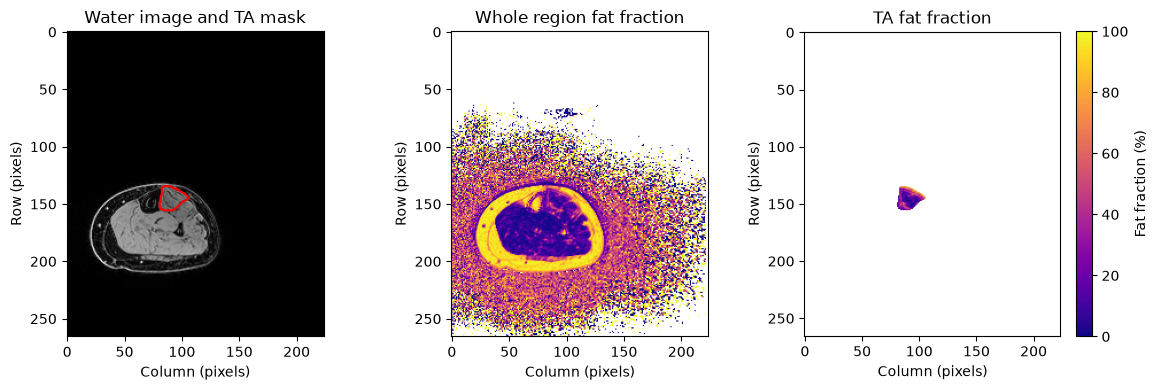

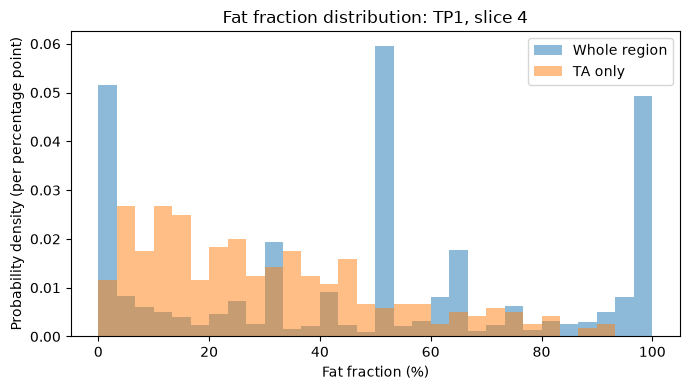

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(water, cmap="gray")
axes[0].contour(mask, levels=[0.5], colors="red")
axes[0].set_title("Water image and TA mask")
image1 = axes[1].imshow(fat_fraction_full, cmap="plasma", vmin=0, vmax=100)
axes[1].set_title("Whole region fat fraction")
image2 = axes[2].imshow(fat_fraction_masked, cmap="plasma", vmin=0, vmax=100)
axes[2].set_title("TA fat fraction")
for ax in axes:
    ax.set_xlabel("Column (pixels)")
    ax.set_ylabel("Row (pixels)")
fig.colorbar(image2, ax=axes[2], label="Fat fraction (%)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.hist(whole_image_values, bins=np.linspace(0, 100, 31), density=True,
         alpha=0.5, label="Whole region")
plt.hist(muscle_values, bins=np.linspace(0, 100, 31), density=True,
         alpha=0.5, label="TA only")
plt.xlabel("Fat fraction (%)")
plt.ylabel("Probability density (per percentage point)")
plt.title("Fat fraction distribution: TP1, slice 4")
plt.legend()
plt.tight_layout()
plt.show()

Figures 1 and 2 show one slice from TP1. The mask separates the TA from surrounding tissue. The histograms show why the whole-region measurement differs from the TA measurement. Density is used because the two regions contain different numbers of pixels.

Next, we repeat the calculation for all slices. We calculate the mean, median, and standard deviation of the valid TA pixels, as well as the number of mask pixels and valid pixels. Standard deviation describes the spread of pixel values, not the uncertainty in the mean. We also keep the whole-region mean for comparison.

,timepoint,slice_id,distance_mm,percent_along_muscle,mean_ff,median_ff,std_ff,n_muscle_pixels,n_valid_pixels,whole_region_mean_ff
0,TP1,1,24.0,10,83.92,88.83,13.27,61,61,50.29
1,TP1,2,44.0,20,82.71,86.65,12.43,115,115,50.15
2,TP1,3,68.0,30,58.50,61.82,22.88,231,231,49.41
3,TP1,4,92.0,40,29.93,25.37,21.58,360,360,48.58
4,TP1,5,116.0,50,20.87,14.55,20.06,421,421,48.47
5,TP1,6,136.0,60,16.76,9.05,19.67,440,440,48.71
6,TP1,7,160.0,70,17.51,8.96,20.46,388,388,49.15
7,TP1,8,184.0,80,27.87,22.69,22.63,263,263,50.00
8,TP2,1,24.0,10,82.39,90.84,15.91,46,46,51.01
9,TP2,2,48.0,20,84.05,92.03,17.74,74,74,50.63


,mean,std
timepoint,,
TP1,42.26,28.57
TP2,54.41,25.08


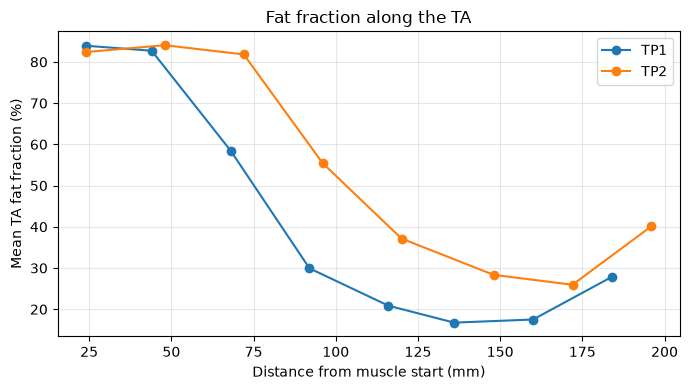

In [3]:
results = []
for _, row in manifest.iterrows():
    water = np.load(DATA_DIR / row["water_file"])
    fat = np.load(DATA_DIR / row["fat_file"])
    mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)
    ff = calculate_fat_fraction(water, fat, mask)
    ff_full = calculate_fat_fraction(water, fat)
    results.append({
        "timepoint": row["timepoint"],
        "slice_id": row["slice_id"],
        "distance_mm": row["distance_from_muscle_start_mm"],
        "percent_along_muscle": row["percent_along_muscle"],
        "mean_ff": np.nanmean(ff),
        "median_ff": np.nanmedian(ff),
        "std_ff": np.nanstd(ff),
        "n_muscle_pixels": int(mask.sum()),
        "n_valid_pixels": int(np.isfinite(ff).sum()),
        "whole_region_mean_ff": np.nanmean(ff_full)
    })

results_df = pd.DataFrame(results)
display(results_df.round(2))
display(results_df.groupby("timepoint")["mean_ff"].agg(["mean", "std"]).round(2))

plt.figure(figsize=(7, 4))
for timepoint, group in results_df.groupby("timepoint"):
    group = group.sort_values("distance_mm")
    plt.plot(group["distance_mm"], group["mean_ff"], marker="o", label=timepoint)
plt.xlabel("Distance from muscle start (mm)")
plt.ylabel("Mean TA fat fraction (%)")
plt.title("Fat fraction along the TA")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Figure 3 shows how mean fat fraction varies along the muscle at both visits. Each point is a measured slice summary. The visit table gives the average and sample standard deviation of the eight slice means. This gives equal weight to each slice and is not a whole-muscle volume average. Slice spacing is unequal, so we use the actual distance in millimeters. TP1 and TP2 do not always have the same distances, so directly subtracting values by slice number would not compare identical positions.

For the project comparison, we use the clinical CSV and actual visit times in months. The MRI image visit labels do not provide elapsed months, so we do not assign them dates or use them to fill missing values in the clinical CSV.

The following code follows the class interpolation example for subject 13-0004, using right-leg fat fraction and right-leg dorsiflexion strength. We use 12 and 24 months instead of the class example's earliest visit times. We remove missing time/value pairs separately for each measure. At least two distinct times are needed.

Linear interpolation uses the line between the two measurements around the target time. Outside the observed times, we extend the nearest end segment and call it extrapolation. This is piecewise linear interpolation, not one regression line fitted to all visits. We assume each visit's lag_months value applies to both measurements because separate dates are not provided.

Fat fraction at 12 months, matrix method: 10.906213205081567


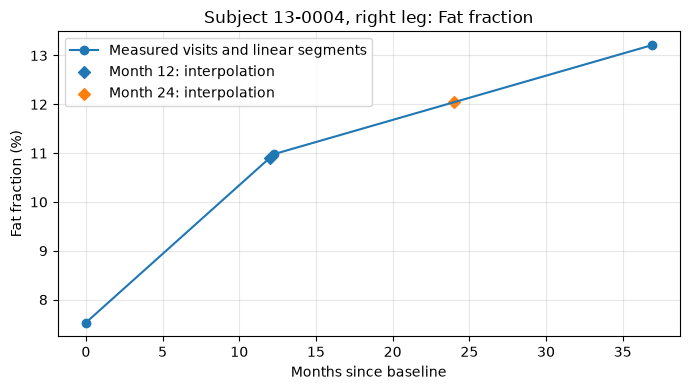

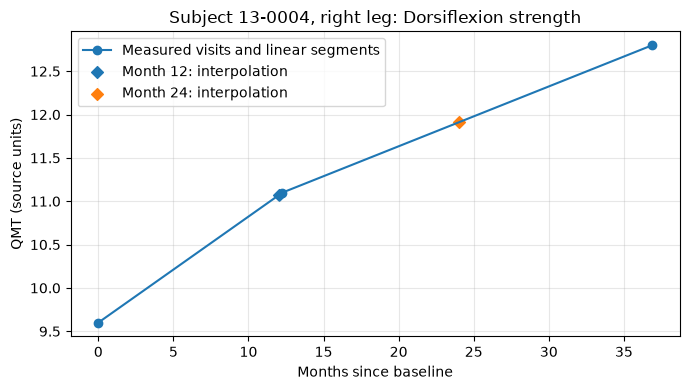

,measure,month,estimate,type,months_outside_data,plausible
0,Fat fraction,12,10.906,interpolation,0,True
1,Fat fraction,24,12.043,interpolation,0,True
2,Dorsiflexion strength,12,11.068,interpolation,0,True
3,Dorsiflexion strength,24,11.910,interpolation,0,True


In [4]:
df = pd.read_csv("Module2_FSHD_Dataset.csv")
row = df.loc[df["subject_id"] == "13-0004"].iloc[0]

lag_months = np.array([row["lag_months_baseline"], row["lag_months_y1"], row["lag_months_y2"]])
ff_values = np.array([row["ff_baseline_R"], row["ff_y1_R"], row["ff_y2_R"]])
strength_values = np.array([row["dorsiflexion_qmt_R_baseline"],
                            row["dorsiflexion_qmt_R_y1"],
                            row["dorsiflexion_qmt_R_y2"]])
T1 = 12
T2 = 24

# The matrix method from the example, using the two points around month 12.
valid = np.isfinite(lag_months) & np.isfinite(ff_values)
x = lag_months[valid]
y = ff_values[valid]
order = np.argsort(x)
x, y = x[order], y[order]
i = int(np.clip(np.searchsorted(x, T1) - 1, 0, len(x) - 2))
x1, x2 = x[i], x[i + 1]
y1, y2 = y[i], y[i + 1]
Z = np.array([[1, x1], [1, x2]])
Y = np.array([y1, y2])
A = np.linalg.solve(Z, Y)
a1, a2 = A
estimate_T1 = a1 + a2 * T1
print("Fat fraction at 12 months, matrix method:", estimate_T1)

# The same approach with interp1d, for both measurements.
estimates = []
for name, values, units in [("Fat fraction", ff_values, "Fat fraction (%)"),
                            ("Dorsiflexion strength", strength_values, "QMT (source units)")]:
    valid = np.isfinite(lag_months) & np.isfinite(values)
    x = lag_months[valid]
    y = values[valid]
    order = np.argsort(x)
    x, y = x[order], y[order]
    if len(x) < 2 or len(np.unique(x)) != len(x):
        for target in [T1, T2]:
            estimates.append({"measure": name, "month": target,
                              "estimate": np.nan, "type": "not enough distinct times"})
        continue

    f_linear = interp1d(x, y, kind="linear", bounds_error=False, fill_value="extrapolate")
    if name == "Fat fraction":
        assert np.isclose(f_linear(T1), estimate_T1)
    plt.figure(figsize=(7, 4))
    plt.plot(x, y, "o-", label="Measured visits and linear segments")
    for target in [T1, T2]:
        estimate = float(f_linear(target))
        outside = max(x[0] - target, target - x[-1], 0)
        estimate_type = "extrapolation" if outside > 0 else "interpolation"
        if np.isclose(x, target).any():
            estimate_type = "observed"
        plausible = 0 <= estimate <= 100 if name == "Fat fraction" else estimate >= 0
        estimates.append({"measure": name, "month": target, "estimate": estimate,
                          "type": estimate_type, "months_outside_data": outside,
                          "plausible": plausible})
        plt.scatter(target, estimate, marker="D", label=f"Month {target}: {estimate_type}")
        if outside > 0:
            end = 0 if target < x[0] else -1
            plt.plot([x[end], target], [y[end], estimate], "--", color="gray")
    plt.xlabel("Months since baseline")
    plt.ylabel(units)
    plt.title("Subject 13-0004, right leg: " + name)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

estimates_df = pd.DataFrame(estimates)
display(estimates_df.round(3))

Figures 4 and 5 show the observed values and the estimates at 12 and 24 months for one participant. Both measures increase in this example, so increasing fat fraction does not necessarily go along with decreasing strength for every person. This example shows the method, not a result for the whole group. Strength is labeled in source units because the CSV does not state the physical units.

For the full analysis, we will repeat this process for each participant and leg. We will compare only matching participants and legs with baseline values and enough data for both measures. Right and left legs will be analyzed separately so they are not counted as independent participants. Missing estimates will remain NaN. We will flag impossible predictions rather than change them, report exclusions, and compare results with and without extrapolated values.

We will calculate fat-fraction change as follow-up minus baseline, and strength decline as baseline minus follow-up. Positive values then mean worsening for both measures. We will compare the proportion showing worsening, the mean change, and the standard deviation of change. Since the units differ, we will also divide changes by each measure's baseline standard deviation in the same matched group. This calculation is only possible if that standard deviation is not zero. A scatterplot of fat-fraction change against strength decline will show whether the changes are related.

The main assumptions are that changes are linear between visits and that the same trend continues when extrapolating. Estimated values are not new measurements. Missing visits, mask accuracy, measurement variability, and longer extrapolation distances can affect the results. This methods example cannot tell us which measure is better across the full group or whether either measure detects a treatment effect.

## Interpolation Analysis:

Explain how interpolation was used to estimate fat fraction or another measurement at a location between sampled points along the tibialis anterior.

Include:

- The variable used to define location along the muscle, such as distance in millimeters or percentage of muscle length
- The sampled locations used as inputs to the interpolation
- The interpolation method and Python code used
- A plot showing the measured values and the interpolated estimate(s)
- Why interpolation is an estimate rather than a new measurement
- The assumptions made about how the measurement changes between sampled locations
- Whether the estimate is within the range of sampled data or represents extrapolation
- Any limitations or sources of uncertainty in the interpolated result

## Conclusions:

Explain what your analysis suggests about measuring FSHD progression.

Discuss:

- Which MRI, biomarker, or functional measures changed most consistently
- Which measures appeared most sensitive to differences across muscle locations or visits
- Whether the measures could be useful as biomarkers or exploratory clinical-trial endpoints
- What additional evidence would be needed before using them to evaluate treatment effectiveness
- Potential ethical implications of selecting one measure over another, including patient relevance, accessibility, and the risk of overlooking meaningful changes in function

## Limitations and Future Work:

Describe the limitations of your project, including limitations of the sample size, available visits, MRI measurements, segmentation, biomarkers, functional measures, and analysis methods.

If you had more time or additional data, explain how you would improve the analysis. Examples include analyzing more participants, adding more timepoints, improving segmentation, comparing additional muscles, validating the MRI measure against functional outcomes, or testing whether the measure is sensitive to treatment response.

## AI Usage Statement:
*This is where you will provide a short description on whether AI (and which AI) was used for any of the sections above and whether it helped or why it did not help.*
- We used ChatGPT (OpenAI, October 15, 2026) to help adapt the class example code for comparing MRI fat fraction and dorsiflexion strength at 12 and 24 months. ChatGPT helped add missing-data checks and linear extrapolation.

## GitHub Repository Link:
[bme2315_module2_fshd]:https://github.com/amccollbrady/bme2315_module2_fshd

https://github.com/amccollbrady/bme2315_module2_fshd

## References:
**References**

1. Deenen et al. (2014). *Population-based incidence and prevalence of facioscapulohumeral dystrophy.*  
   [PubMed](https://pubmed.ncbi.nlm.nih.gov/25122204/)

2. Preston, M. K., & Wang, L. H. (2025). *Facioscapulohumeral muscular dystrophy.* GeneReviews.  
   [NCBI Bookshelf](https://www.ncbi.nlm.nih.gov/books/NBK1443/)

3. Giardina et al. (2024). *Best practice guidelines on genetic diagnostics of facioscapulohumeral muscular dystrophy: Update of the 2012 guidelines.*  
   [PubMed](https://pubmed.ncbi.nlm.nih.gov/38685133/)

4. Medicare. *Medicare coverage of therapy services.*  
   [Medicare fact sheet](https://www.medicare.gov/publications/10988-medicare-coverage-of-therapy-services.pdf)

5. Medicare. *Braces (arm, leg, back, & neck).*  
   [Medicare coverage information](https://www.medicare.gov/coverage/braces-arm-leg-back-neck)

6. *Genetic and epigenetic contributors to FSHD.* (2015).  
   [PubMed Central](https://pmc.ncbi.nlm.nih.gov/articles/PMC4674299/)

7. *DUX4 signalling in the pathogenesis of facioscapulohumeral muscular dystrophy.* (2020).  
   [PubMed Central](https://pmc.ncbi.nlm.nih.gov/articles/PMC7037115/)

8. Novartis. (2026, June 11). *Novartis delpacibart braxlosiran (del-brax) Phase I/II study in facioscapulohumeral muscular dystrophy (FSHD) meets primary biomarker endpoint.* [Press release].  
   [Novartis](https://www.novartis.com/news/media-releases/novartis-delpacibart-braxlosiran-del-brax-phase-iii-study-facioscapulohumeral-muscular-dystrophy-fshd-meets-primary-biomarker-endpoint)

9. Fulcrum Therapeutics. (2024, September 12). *Fulcrum Therapeutics announces topline results from Phase 3 REACH clinical trial of losmapimod in facioscapulohumeral muscular dystrophy (FSHD).* [Press release].  
   [Fulcrum Therapeutics](https://ir.fulcrumtx.com/news-releases/news-release-details/fulcrum-therapeutics-announces-topline-results-phase-3-reach)